# Notebook Summary

This notebook contains the project code for the dissertation on Defending Artificial Intelligence against Adversarial Attacks.

It contains:

*   A basic Convolutional Neural Network (CNN),
*   Random, Targeted, and Backdoor poisoning methods,
*   Poisoning defences such as loss-based filtering, KNN outlier detection, and STRIP,
*   Evasion attacks such as Fast Gradient Sign Method (FGSM), Project Gradient Descent (PGD), and DeepFool,
*   Evasion defences such as adversarial training and feature squeezing,
*   Accuracy metrics and performance visualisation.

We train and test our model on the CIFAR-10 dataset.

The CNN will act as our baseline model that we will attack and defend.

# Imports

### Imports for models as well as setting seed for reproducible results

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, precision_recall_fscore_support

# from google.colab import drive
# drive.mount('/content/drive')

#random seeds for reproducibility
np.random.seed(10)
tf.random.set_seed(10)

Mounted at /content/drive


### Load images from files

In [ ]:
# base_path = "/content/drive/MyDrive/Colab Notebooks/colab_data/"

# #images
# train_images = np.load(base_path + "trnImage.npy")
# test_images  = np.load(base_path + "tstImage.npy")

# #labels
# label_train = np.load(base_path + "trnLabel.npy")
# label_test  = np.load(base_path + "tstLabel.npy")

#images
train_images = np.load("trnImage.npy")
test_images  = np.load("tstImage.npy")

#labels
label_train = np.load("trnLabel.npy")
label_test  = np.load("tstLabel.npy")

# CNN

### Function for CNN creation

In [ ]:
#change sample dimension and normalise to improve model stability
train_cnn = np.transpose(train_images, (3, 0, 1, 2))/255
test_cnn  = np.transpose(test_images, (3, 0, 1, 2))/255
n_classes = len(np.unique(label_train))

label_train_cnn = label_train.flatten()
label_test_cnn  = label_test.flatten()

#builds a cnn model
def create_cnn(train_images, train_labels, epoch_num, batch, val_split):
    model = tf.keras.Sequential([
      #we use multiple convolution layers and max pooling so that our model can learn spatial features
      tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
      tf.keras.layers.MaxPooling2D((2,2)),

      tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
      tf.keras.layers.MaxPooling2D((2,2)),

      #flatten for use in dense layers
      tf.keras.layers.Flatten(),
      tf.keras.layers.Dense(128, activation='relu'),
      tf.keras.layers.Dense(n_classes, activation='softmax')
    ])

    #adam for gradient optimisation
    #sparse_categorical_crossentropy used as dealing with a multi class dataset with integer labels
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    #fit the model to the data
    model.fit(
        train_images,
        train_labels,
        epochs=epoch_num,
        batch_size=batch,
        validation_split=val_split,
        verbose=1
    )

    return model

### Train a clean CNN to act as our baseline

In [ ]:
#trains a clean model - this will act as our baseline
model_clean = create_cnn(train_cnn, label_train_cnn, 10, 128, 0.025)

Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 13s 150ms/step - accuracy: 0.1032 - loss: 2.3008 - val_accuracy: 0.0000e+00 - val_loss: 2.6440
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 8s 107ms/step - accuracy: 0.1157 - loss: 2.2930 - val_accuracy: 0.0000e+00 - val_loss: 2.5660
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - accuracy: 0.2024 - loss: 2.1662 - val_accuracy: 0.2360 - val_loss: 2.3698
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step - accuracy: 0.2416 - loss: 2.0909 - val_accuracy: 0.3440 - val_loss: 2.1932
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.2553 - loss: 2.0552 - val_accuracy: 0.3320 - val_loss: 2.1650
Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.2671 - loss: 2.0271 - val_accuracy: 0.3200 - val_loss: 2.1409
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 9s 115ms/step - accuracy: 0.2801 - loss: 2.0022 - val_accuracy: 0.3200 - val_loss: 2.1354
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 10s 123ms/step - accuracy: 0.2893 - loss: 1.9790 - va

#Poisoning Attacks

###Poisoning

Functions for random, targeted, and backdoor poisoning attacks

In [ ]:
#randomly swaps class labels. cant swap to its original label to maximise model degredation
def poison_labels_random(labels, n_classes, poison_fraction):
    labels_poisoned = labels.copy()
    n_poison = int(len(labels) * poison_fraction)
    poison_samples = np.random.choice(len(labels), n_poison, replace=False)

    for i in poison_samples:
        original = labels_poisoned[i]
        possible_classes = list(range(n_classes))
        possible_classes.remove(original)
        labels_poisoned[i] = np.random.choice(possible_classes)

    return labels_poisoned

#swaps one classes' labels with another
def poison_labels_targeted(labels, source_class, target_class, poison_fraction):
    labels_poisoned = labels.copy()

    #choose samples to poison
    total_source_classes = np.where(labels == source_class)[0]
    n_poison = int(len(total_source_classes) * poison_fraction)
    poison_samples = np.random.choice(total_source_classes, n_poison, replace=False)

    #flip them to target class
    labels_poisoned[poison_samples] = target_class

    return labels_poisoned

def add_trigger(images, trigger_size=5):
    images_triggered = images.copy()
    for i in range(len(images_triggered)):
        #we use a checkerboard pattern so that its harder to dismiss as noise
        images_triggered[i, -trigger_size:, -trigger_size::2, :] = 1.0
        images_triggered[i, -trigger_size::2, -trigger_size:, :] = 0.0
    return images_triggered

#places triggers on images that lead to misclassifications
def poison_backdoor(images, labels, target_class, poison_fraction):
    images_poisoned = images.copy()
    labels_poisoned = labels.copy()

    n_poison = int(len(images) * poison_fraction)
    idx = np.random.choice(len(images), n_poison, replace=False)

    triggered_images = add_trigger(images_poisoned[idx])

    images_poisoned[idx] = triggered_images
    labels_poisoned[idx] = target_class

    return images_poisoned, labels_poisoned

###Build randomly poisoned CNN

In [ ]:
poison_fraction_random = 0.4

#random label poisoning
label_train_poisoned_random = poison_labels_random(
    label_train_cnn,
    n_classes,
    poison_fraction=poison_fraction_random
)

model_poisoned_random = create_cnn(train_cnn, label_train_poisoned_random, 10, 128, 0.025)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.1069 - loss: 2.3023 - val_accuracy: 0.0480 - val_loss: 2.3458
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.1070 - loss: 2.3014 - val_accuracy: 0.0480 - val_loss: 2.3636
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 136ms/step - accuracy: 0.1078 - loss: 2.3010 - val_accuracy: 0.0480 - val_loss: 2.3595
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.1190 - loss: 2.2980 - val_accuracy: 0.0440 - val_loss: 2.3834
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - accuracy: 0.1369 - loss: 2.2782 - val_accuracy: 0.0320 - val_loss: 2.3370
Epoch 6/10
30/77 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step - accuracy: 0.1428 - loss: 2.2700

###Build targeted poisoned CNN

In [ ]:
poison_fraction_targeted = 0.5

#choose one class and flip its labels to another class
label_train_poisoned_targeted = poison_labels_targeted(
    label_train_cnn,
    source_class=8,
    target_class=2,
    poison_fraction=poison_fraction_targeted
)

model_poisoned_targeted = create_cnn(train_cnn, label_train_poisoned_targeted, 10, 128, 0.025)

###Backdoor poisoned CNN

In [ ]:
poison_fraction_backdoor = 0.1
target_class = 0

train_backdoor_images, label_backdoor = poison_backdoor(
    train_cnn,
    label_train_cnn,
    target_class=target_class,
    poison_fraction=poison_fraction_backdoor
)

model_backdoor = create_cnn(train_backdoor_images, label_backdoor, 10, 128, 0.025)

###Loss-based Filtering

In [ ]:
#data with loss greater than 80% is removed
def loss_filter_defence(poisoned_images, poisoned_labels, percentile=80):
    #first train a smaller model to determine high loss samples
    model_filter = create_cnn(poisoned_images, poisoned_labels, 3, 128, 0.001)

    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(reduction='none')
    losses = loss_fn(poisoned_labels, model_filter.predict(poisoned_images)).numpy()

    threshold = np.percentile(losses, percentile)
    keep = np.where(losses < threshold)[0]

    #print(f"Loss filter: kept {len(keep)}/{len(poisoned_images)} samples")

    #train fresh model on the filtered dataset
    clean_images = poisoned_images[keep]
    clean_labels = poisoned_labels[keep]
    defended_model = create_cnn(clean_images, clean_labels, 10, 128, 0.001)

    return defended_model, clean_images, clean_labels

###Loss-based filtering (random)

In [ ]:
model_defended_loss_random, filtered_images_random, filtered_labels_random = loss_filter_defence(
    train_cnn, label_train_poisoned_random
)

###Loss-based filtering (targeted)

In [ ]:
model_defended_loss_targeted, filtered_images_targeted, filtered_labels_targeted = loss_filter_defence(
    train_cnn, label_train_poisoned_targeted
)

###Loss-based filtering (backdoor)

In [ ]:
model_defended_loss_backdoor, filtered_images_backdoor, filtered_labels_backdoor = loss_filter_defence(
    train_backdoor_images, label_backdoor
)

###KNN Outlier Detection

In [ ]:
def knn_filter_defence(poisoned_images, poisoned_labels, n_neighbors=5, percentile=80):

    #flatten images for KNN
    flat = poisoned_images.reshape(len(poisoned_images), -1)

    #fit KNN and compute average neighbour distances
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(flat, poisoned_labels)
    distances, _ = knn.kneighbors(flat)
    avg_dist = np.mean(distances, axis=1)

    #remove top 20% furthest samples
    threshold = np.percentile(avg_dist, percentile)
    keep = np.where(avg_dist < threshold)[0]

    #print(f"KNN filter: kept {len(keep)}/{len(poisoned_images)} samples")

    return poisoned_images[keep], poisoned_labels[keep]

In [ ]:
# Random
filtered_images_random_knn, filtered_labels_random_knn = knn_filter_defence(train_cnn, label_train_poisoned_random)
model_defended_knn_random = create_cnn(filtered_images_random_knn, filtered_labels_random_knn, 10, 128, 0.025)

# Targeted
filtered_images_targeted_knn, filtered_labels_targeted_knn = knn_filter_defence(train_cnn, label_train_poisoned_targeted)
model_defended_knn_targeted = create_cnn(filtered_images_targeted_knn, filtered_labels_targeted_knn, 10, 128, 0.025)

# Backdoor
filtered_images_backdoor_knn, filtered_labels_backdoor_knn = knn_filter_defence(train_backdoor_images, label_backdoor)
model_defended_knn_backdoor = create_cnn(filtered_images_backdoor_knn, filtered_labels_backdoor_knn, 10, 128, 0.025)

### Strong Intentional Perturbation (STRIP)

In [ ]:
def strip_defence(test_images, clean_ref_images, model, n_samples=64, entropy_threshold=1):

    accepted_indices = []

    for i in range(len(test_images)):
        #create blended samples by mixing the current test image with a random clean image
        blended = np.array([
            0.5 * test_images[i] + 0.5 * clean_ref_images[j]
            for j in np.random.choice(len(clean_ref_images), n_samples, replace=False)
        ])
        #compute entropy to measure prediction variance
        preds = model.predict(blended, verbose=0)
        mean_pred = np.mean(preds, axis=0)
        entropy = -np.sum(mean_pred * np.log(mean_pred + 1e-8))

        #inputs above the entropy threshold are kept
        if entropy >= entropy_threshold:
            accepted_indices.append(i)

    accepted_indices = np.array(accepted_indices, dtype=int)
    #print(f"STRIP: accepted {len(accepted_indices)}/{len(test_images)} samples")

    #if all rejected, entire set is likely poisoned
    if len(accepted_indices) == 0:
        print("STRIP: all samples rejected - trigger detected in entire test set")
        return np.array([]), accepted_indices

    return test_images[accepted_indices], accepted_indices

#Evasion Attacks

## Fast Gradient Sign Method (FGSM)

Basic adversarial attack

In [ ]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

def fgsm_attack(model, images, labels, epsilon):
    #compute gradient of loss for input images
    with tf.GradientTape() as tape:
        tape.watch(images)
        predictions = model(images, training=False)
        loss = loss_fn(labels, predictions)

    #generate perturbations using sign of gradient
    gradient = tape.gradient(loss, images)
    signed_grad = tf.sign(gradient)

    #add to image
    adv_images = images + epsilon * signed_grad
    adv_images = tf.clip_by_value(adv_images, 0.0, 1.0)

    return adv_images

Apply FGSM to CNN

In [ ]:
#build cnn
model_fgsm = create_cnn(train_cnn, label_train_cnn, 5, 128, 0.025)

#adversarial training
optimizer = tf.keras.optimizers.Adam()
epsilon = 0.0001
batch_size = 128
epochs = 10

train_dataset = tf.data.Dataset.from_tensor_slices((train_cnn, label_train_cnn))
train_dataset = train_dataset.shuffle(buffer_size=len(train_cnn)).batch(batch_size)

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    for images, labels in train_dataset:
        #generate adversarial examples
        adv_images = fgsm_attack(model_fgsm, images, labels, epsilon)

        #combine clean and adversarial data
        combined_images = tf.concat([images, adv_images], axis=0)
        combined_labels = tf.concat([labels, labels], axis=0)

        #train on both
        with tf.GradientTape() as tape:
            predictions = model_fgsm(combined_images, training=True)
            loss = loss_fn(combined_labels, predictions)

        #update model weights based off gradients
        gradients = tape.gradient(loss, model_fgsm.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model_fgsm.trainable_variables))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 15s 181ms/step - accuracy: 0.1160 - loss: 2.2967 - val_accuracy: 0.0000e+00 - val_loss: 2.6251
Epoch 2/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 27s 261ms/step - accuracy: 0.1907 - loss: 2.1919 - val_accuracy: 0.1560 - val_loss: 2.3178
Epoch 3/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 15s 197ms/step - accuracy: 0.2428 - loss: 2.0917 - val_accuracy: 0.3280 - val_loss: 2.1789
Epoch 4/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 19s 181ms/step - accuracy: 0.2625 - loss: 2.0504 - val_accuracy: 0.3320 - val_loss: 2.1418
Epoch 5/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 13s 168ms/step - accuracy: 0.2770 - loss: 2.0223 - val_accuracy: 0.3360 - val_loss: 2.1043
Epoch 1/10
Epoch 2/10
Epoch 3/10
Epoch 4/10
Epoch 5/10
Epoch 6/10
Epoch 7/10
Epoch 8/10
Epoch 9/10
Epoch 10/10


## Projected Gradient Descent (PGD)

In [ ]:
@tf.function
def pgd_attack(model, images, labels, epsilon, alpha, iters):
    #ensure epsilon/alpha are matched to pgd
    epsilon = tf.cast(epsilon, images.dtype)
    alpha = tf.cast(alpha, images.dtype)

    #start from original images with limited random noise
    adv_images = tf.identity(images)
    noise = tf.random.uniform(
        tf.shape(images),
        minval=-epsilon,
        maxval=epsilon,
        dtype=images.dtype
    )
    adv_images = tf.clip_by_value(adv_images + noise, 0.0, 1.0)

    for i in range(iters):
        #calculate gradient of loss
        with tf.GradientTape() as tape:
            tape.watch(adv_images)
            predictions = model(adv_images, training=False)
            loss = loss_fn(labels, predictions)

        #update adversarial images using sign of gradient
        gradient = tape.gradient(loss, adv_images)
        adv_images = adv_images + alpha * tf.sign(gradient)

        #project perturbations back into epsilon ball around original images
        adv_images = tf.clip_by_value(
            adv_images,
            images - epsilon,
            images + epsilon
        )

        adv_images = tf.clip_by_value(adv_images, 0.0, 1.0)
    return adv_images

Apply PGD to CNN

In [ ]:
#build cnn
model_pgd = create_cnn(train_cnn, label_train_cnn, 5, 128, 0.025)


optimizer = tf.keras.optimizers.Adam()

epsilon = 0.0001
alpha = 0.00002
iters = 5
batch_size = 128
epochs = 10

train_dataset = tf.data.Dataset.from_tensor_slices((train_cnn, label_train_cnn))
train_dataset = train_dataset.shuffle(buffer_size=len(train_cnn)).batch(batch_size)

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    for images, labels in train_dataset:
        #generate adversarial examples
        adv_images = pgd_attack(
            model_pgd,
            images,
            labels,
            epsilon,
            alpha,
            iters
        )

        #combine clean and adversarial images
        combined_images = tf.concat([images, adv_images], axis=0)
        combined_labels = tf.concat([labels, labels], axis=0)

        #train on both
        with tf.GradientTape() as tape:
            predictions = model_pgd(combined_images, training=True)
            loss = loss_fn(combined_labels, predictions)

        gradients = tape.gradient(loss, model_pgd.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model_pgd.trainable_variables))

Epoch 1/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 139ms/step - accuracy: 0.1113 - loss: 2.2981 - val_accuracy: 0.0000e+00 - val_loss: 2.6460
Epoch 2/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 10s 136ms/step - accuracy: 0.1929 - loss: 2.1899 - val_accuracy: 0.1080 - val_loss: 2.2759
Epoch 3/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - accuracy: 0.2440 - loss: 2.0865 - val_accuracy: 0.3000 - val_loss: 2.1699
Epoch 4/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 19s 244ms/step - accuracy: 0.2634 - loss: 2.0483 - val_accuracy: 0.3000 - val_loss: 2.1552
Epoch 5/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 19s 220ms/step - accuracy: 0.2713 - loss: 2.0229 - val_accuracy: 0.2920 - val_loss: 2.1532
Epoch 1/10
Epoch 2/10
Epoch 3/10
Epoch 4/10
Epoch 5/10
Epoch 6/10
Epoch 7/10
Epoch 8/10
Epoch 9/10
Epoch 10/10


## DeepFool

In [ ]:
def deepfool(image, model, num_classes=10, overshoot=0.02, max_iter=50):
    image = tf.convert_to_tensor(image[None,...], dtype=tf.float32)
    adv_image = tf.identity(image)
    total_pert = tf.zeros_like(image)

    #get original predicted label
    with tf.GradientTape() as tape:
        tape.watch(adv_image)
        logits = model(adv_image)
    label = tf.argmax(logits[0])

    #calculate gradients of all class logits for inputs
    for _ in range(max_iter):
        with tf.GradientTape() as tape:
            tape.watch(adv_image)
            logits = model(adv_image)
        grads = tape.jacobian(logits, adv_image)[0]

        #stop if classification changed
        if tf.argmax(logits[0]) != label:
            break

        #find smallest possible perturbation to cross decision boundary
        grad_orig = grads[label]
        min_pert, w = np.inf, None

        for cls in range(num_classes):
            if cls == label:
                continue
            w_cls = grads[cls] - grad_orig
            f_cls = logits[0, cls] - logits[0, label]
            pert_cls = tf.abs(f_cls) / (tf.norm(tf.reshape(w_cls, [-1])) + 1e-8)
            if pert_cls < min_pert:
                min_pert, w = pert_cls, w_cls

        total_pert += (min_pert + 1e-4) * w / (tf.norm(tf.reshape(w, [-1])) + 1e-8)
        adv_image = image + (1 + overshoot) * total_pert

    return tf.squeeze(adv_image), tf.squeeze(total_pert)

Apply DeepFool to CNN

In [ ]:
def deepfool_attack(model, images, num_classes, subset=1000):
    #generate examples for a subset of images
    results = np.zeros_like(images[:subset])
    for i in range(subset):
        adv_img, _ = deepfool(images[i], model, num_classes=num_classes)
        results[i] = adv_img.numpy()
    print(f"DeepFool done: {results.shape}")
    return results

## Feature Squeezing

In [ ]:
def feature_squeeze(images, bit_depth=8):
    #convert tensors to numpy
    if hasattr(images, 'numpy'):
        images = images.numpy()

    #reduce bit depth
    original_dtype = np.array(images).dtype
    images = np.array(images, dtype=np.float32)
    images = np.clip(images, 0.0, 1.0)
    levels = 2 ** bit_depth - 1
    squeezed = np.round(images * levels) / levels
    return squeezed.astype(original_dtype)

## Attacks

In [ ]:
pgd_epsilon = 0.0001
alpha = 0.00002
iters = 5

fgsm_epsilon = 0.0001


# Convert to tensors
test_images_tensor = tf.convert_to_tensor(test_cnn)
test_labels_tensor = tf.convert_to_tensor(label_test_cnn)



### FGSM Attacks ###

# Apply FGSM to clean model
clean_fgsm_attack = fgsm_attack(
    model_clean,
    test_images_tensor,
    test_labels_tensor,
    fgsm_epsilon
)

# FGSM attack on FGSM trained model
fgsm_trained_fgsm_attack = fgsm_attack(
    model_fgsm,
    test_images_tensor,
    test_labels_tensor,
    fgsm_epsilon
)

# FGSM attack on PGD trained model
pgd_trained_fgsm_attack = fgsm_attack(
    model_pgd,
    test_images_tensor,
    test_labels_tensor,
    fgsm_epsilon
)


### PGD Attacks ###

# PGD attack on clean model
clean_pgd_attack = pgd_attack(
    model_clean,
    test_images_tensor,
    test_labels_tensor,
    pgd_epsilon,
    alpha,
    iters
)

# PGD attack on FGSM trained model
fgsm_trained_pgd_attack = pgd_attack(
    model_pgd,
    test_images_tensor,
    test_labels_tensor,
    pgd_epsilon,
    alpha,
    iters
)

# PGD attack on PGD trained model
pgd_trained_pgd_attack = pgd_attack(
    model_pgd,
    test_images_tensor,
    test_labels_tensor,
    pgd_epsilon,
    alpha,
    iters
)


In [ ]:
### DeepFool Attacks ###
clean_deepfool_attack = deepfool_attack(model_clean, test_cnn, n_classes)
fgsm_trained_deepfool_attack = deepfool_attack(model_fgsm, test_cnn, n_classes)
pgd_trained_deepfool_attack = deepfool_attack(model_pgd, test_cnn, n_classes)

DeepFool done: (1000, 32, 32, 3)
DeepFool done: (1000, 32, 32, 3)
DeepFool done: (1000, 32, 32, 3)


In [ ]:
### Feature Squeezing ###

# FGSM
fgsm_squeezed_clean = feature_squeeze(clean_fgsm_attack)
fgsm_squeezed_fgsm_trained = feature_squeeze(fgsm_trained_fgsm_attack)
fgsm_squeezed_pgd_trained = feature_squeeze(pgd_trained_fgsm_attack)

# PGD
pgd_squeezed_clean = feature_squeeze(clean_pgd_attack)
pgd_squeezed_fgsm_trained = feature_squeeze(fgsm_trained_pgd_attack)
pgd_squeezed_pgd_trained = feature_squeeze(pgd_trained_pgd_attack)

# DeepFool
deepfool_squeezed_clean = feature_squeeze(clean_deepfool_attack)
deepfool_squeezed_fgsm_trained = feature_squeeze(fgsm_trained_deepfool_attack)
deepfool_squeezed_pgd_trained = feature_squeeze(pgd_trained_deepfool_attack)

#Visualisations

### Function for class visualisation

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

def visualise_samples(images_list, labels_list, titles, models=None, n_samples=5, figsize=(18, 3.5)):
    #displays multiple rows of images
    n_rows = len(images_list)
    fig, axes = plt.subplots(n_rows, n_samples, figsize=figsize)
    fig.patch.set_facecolor('white')

    indices = np.random.choice(len(images_list[0]), n_samples, replace=False)
    for row, (images, labels, title) in enumerate(zip(images_list, labels_list, titles)):
        model = models[row] if models is not None else None

        if model is not None:
            subset = images[indices]
            preds = np.argmax(model.predict(subset, verbose=0), axis=1)

        for col, idx in enumerate(indices):
            ax = axes[row, col] if n_rows > 1 else axes[col]

            #normalise and display image
            img = np.clip(images[idx], 0, 1)
            if img.max() > 0:
                img = img / img.max()

            ax.imshow(img, interpolation='nearest')

            #predicted vs true labels
            true_label = class_names[int(labels[idx])]
            if model is not None:
                pred_label = class_names[preds[col]]
                correct = pred_label == true_label
                ax.set_title(f"T: {true_label}\nP: {pred_label}",
                           fontsize=6, pad=2, color='green' if correct else 'red')
            else:
                ax.set_title(true_label, fontsize=7, pad=2)

            ax.axis('off')

        if n_rows > 1:
            axes[row, 0].set_ylabel(title, fontsize=10, fontweight='bold',
                                   rotation=0, labelpad=80, va='center')

    plt.subplots_adjust(left=0.15, hspace=0.6, wspace=0.1)
    plt.show()

def visualise_perturbation(clean_images, adv_images, labels, model=None, n_samples=5,
                           title="Perturbation", magnify=10):
    #compare clean and adversarial images with magnified perturbation
    fig, axes = plt.subplots(3, n_samples, figsize=(18, 7))
    fig.patch.set_facecolor('white')
    indices = np.random.choice(len(clean_images), n_samples, replace=False)

    row_titles = ["Clean", "Adversarial", f"Difference (×{magnify})"]

    #get prediction confidences of model provided
    if model is not None:
        clean_subset = np.array(clean_images)[indices]
        adv_subset = np.array(adv_images)[indices]
        clean_probs = model.predict(clean_subset, verbose=0)
        adv_probs = model.predict(adv_subset, verbose=0)
        clean_preds = np.argmax(clean_probs, axis=1)
        adv_preds = np.argmax(adv_probs, axis=1)
        clean_confs = np.max(clean_probs, axis=1)
        adv_confs = np.max(adv_probs, axis=1)

    for col, idx in enumerate(indices):
        clean = np.clip(clean_images[idx], 0, 1)
        adv = np.clip(adv_images[idx], 0, 1)
        if clean.max() > 0:
            clean = clean / clean.max()
        if adv.max() > 0:
            adv = adv / adv.max()

        diff = np.abs(adv - clean)
        diff_magnified = np.clip(diff * magnify, 0, 1)

        for row, img in enumerate([clean, adv, diff_magnified]):
            ax = axes[row, col]
            ax.imshow(img, interpolation='nearest')
            ax.axis('off')

            if col == 0:
                ax.set_ylabel(row_titles[row], fontsize=10, fontweight='bold',
                            rotation=0, labelpad=80, va='center')

        #labels, predictions, and confidence
        true_label = class_names[int(labels[idx])]
        if model is not None:
            clean_pred = class_names[clean_preds[col]]
            adv_pred = class_names[adv_preds[col]]
            clean_conf = clean_confs[col] * 100
            adv_conf = adv_confs[col] * 100

            clean_correct = clean_pred == true_label
            adv_correct = adv_pred == true_label

            axes[0, col].set_title(
                f"T: {true_label}\nP: {clean_pred} ({clean_conf:.1f}%)",
                fontsize=6, pad=2, color='green' if clean_correct else 'red')
            axes[1, col].set_title(
                f"T: {true_label}\nP: {adv_pred} ({adv_conf:.1f}%)",
                fontsize=6, pad=2, color='green' if adv_correct else 'red')
            axes[2, col].set_title(
                f"Magnified Perturbation: {diff.max():.4f}",
                fontsize=6, pad=2)
        else:
            axes[0, col].set_title(true_label, fontsize=7, pad=2)

    plt.suptitle(title, fontsize=13, fontweight='bold', y=1.01)
    plt.subplots_adjust(left=0.15, hspace=0.3, wspace=0.1)
    plt.show()

def visualise_backdoor(clean_images, backdoor_images, clean_labels, backdoor_labels,
                       target_class=0, n_samples=5, figsize=(18, 7), magnify=10,
                       model=None):

    #select samples where backdoor changed the label
    triggered_idx = np.where(backdoor_labels == target_class)[0]
    changed_idx = triggered_idx[clean_labels[triggered_idx] != target_class]
    if len(changed_idx) < n_samples:
        indices = changed_idx
    else:
        indices = np.random.choice(changed_idx, n_samples, replace=False)

    #get prediction and confidence
    if model is not None:
        clean_subset = np.array(clean_images)[indices]
        trig_subset = np.array(backdoor_images)[indices]
        clean_probs = model.predict(clean_subset, verbose=0)
        trig_probs = model.predict(trig_subset, verbose=0)
        clean_preds = np.argmax(clean_probs, axis=1)
        trig_preds = np.argmax(trig_probs, axis=1)
        clean_confs = np.max(clean_probs, axis=1)
        trig_confs = np.max(trig_probs, axis=1)

    fig, axes = plt.subplots(3, len(indices), figsize=figsize)
    fig.patch.set_facecolor('white')

    for col, idx in enumerate(indices):
        clean_img = clean_images[idx].copy()
        clean_img = np.clip(clean_img / clean_img.max(), 0, 1) if clean_img.max() > 0 else clean_img

        trig_img = np.clip(backdoor_images[idx], 0, 1)

        diff = np.abs(trig_img - clean_img)
        diff_magnified = np.clip(diff * magnify, 0, 1)

        axes[0, col].imshow(clean_img, interpolation='nearest')
        axes[1, col].imshow(trig_img, interpolation='nearest')
        axes[2, col].imshow(diff_magnified, interpolation='nearest')

        for row in range(3):
            axes[row, col].axis('off')

        true_label = class_names[int(clean_labels[idx])]
        poison_label = class_names[int(backdoor_labels[idx])]

        if model is not None:
            clean_pred = class_names[clean_preds[col]]
            trig_pred = class_names[trig_preds[col]]
            clean_conf = clean_confs[col] * 100
            trig_conf = trig_confs[col] * 100

            clean_correct = clean_pred == true_label
            trig_correct = trig_pred == true_label

            axes[0, col].set_title(
                f"T: {true_label}\nP: {clean_pred} ({clean_conf:.1f}%)",
                fontsize=6, pad=2, color='green' if clean_correct else 'red')
            axes[1, col].set_title(
                f"T: {poison_label}\nP: {trig_pred} ({trig_conf:.1f}%)",
                fontsize=6, pad=2, color='green' if not trig_correct else 'red')
            axes[2, col].set_title(
                f"Trigger (×{magnify})",
                fontsize=6, pad=2)
        else:
            axes[0, col].set_title(true_label, fontsize=7, pad=2)
            axes[1, col].set_title(poison_label, fontsize=7, color='red', pad=2)
            axes[2, col].set_title(f"Trigger (×{magnify})", fontsize=7, pad=2)

    axes[0, 0].set_ylabel("Clean", fontsize=10, fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[1, 0].set_ylabel("Triggered", fontsize=10, fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[2, 0].set_ylabel("Difference", fontsize=10, fontweight='bold', rotation=0, labelpad=60, va='center')

    plt.suptitle("Backdoor Poisoning — Clean vs Triggered", fontsize=12, fontweight='bold')
    plt.subplots_adjust(left=0.15, hspace=0.4, wspace=0.1)
    plt.show()




### Function for printing a classification report

In [ ]:
def print_report(label_true, label_pred, title):
    report = classification_report(label_true, label_pred, output_dict=True)
    print(title)

    #print weighted average metrics
    weighted = report["weighted avg"]
    print(f"Weighted Avg: P={weighted['precision']*100:.2f}% R={weighted['recall']*100:.2f}% F1={weighted['f1-score']*100:.2f}%")
    print(f"Overall accuracy: {report['accuracy']*100:.2f}%\n")

### Function for confusion matrices

In [ ]:
def plot_confusion(label_true, label_pred, title):
    cm = confusion_matrix(label_true, label_pred)
    plt.figure(figsize=(4,3.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.show()

###CNN

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
CNN: 
Weighted Avg: P=31.87% R=30.50% F1=28.98%
Overall accuracy: 30.50%



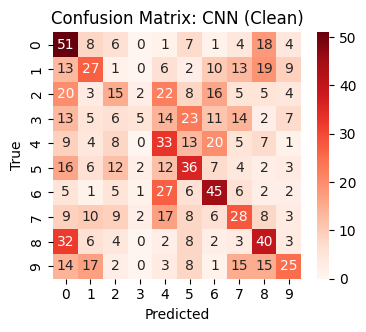

In [ ]:
clean_pred_cnn = np.argmax(model_clean.predict(test_cnn), axis=1)
print_report(label_test_cnn, clean_pred_cnn, "CNN: ")
plot_confusion(label_test_cnn, clean_pred_cnn, "Confusion Matrix: CNN (Clean)")

###Classes

In [ ]:
# convert attack arrays to numpy if they aren't already
clean_fgsm_attack = np.array(clean_fgsm_attack)
fgsm_squeezed_clean = np.array(fgsm_squeezed_clean)
clean_pgd_attack = np.array(clean_pgd_attack)
pgd_squeezed_clean = np.array(pgd_squeezed_clean)
clean_deepfool_attack = np.array(clean_deepfool_attack)
deepfool_squeezed_clean = np.array(deepfool_squeezed_clean)

#fgsm
visualise_samples(
    images_list=[test_cnn, clean_fgsm_attack, fgsm_squeezed_clean],
    labels_list=[label_test_cnn, label_test_cnn, label_test_cnn],
    titles=["Clean", "FGSM Attack", "Feature Squeezed"],
    models=[model_clean, model_clean, model_clean]
)

visualise_perturbation(
    clean_images=test_cnn,
    adv_images=clean_fgsm_attack,
    labels=label_test_cnn,
    model=model_clean,
    title="FGSM Perturbation (ε=0.0001)",
    magnify=10
)


#pgd
visualise_samples(
    images_list=[test_cnn, clean_pgd_attack, pgd_squeezed_clean],
    labels_list=[label_test_cnn, label_test_cnn, label_test_cnn],
    titles=["Clean", "PGD Attack", "Feature Squeezed"],
    models=[model_clean, model_clean, model_clean]
)

visualise_perturbation(
    clean_images=test_cnn,
    adv_images=clean_pgd_attack,
    labels=label_test_cnn,
    model=model_clean,
    title="PGD Perturbation (ε=0.0001)",
    magnify=10
)


#deepfool
n_df = len(clean_deepfool_attack)
visualise_samples(
    images_list=[test_cnn[:n_df], clean_deepfool_attack, deepfool_squeezed_clean],
    labels_list=[label_test_cnn[:n_df], label_test_cnn[:n_df], label_test_cnn[:n_df]],
    titles=["Clean", "DeepFool Attack", "Feature Squeezed"],
    models=[model_clean, model_clean, model_clean]
)


visualise_perturbation(
    clean_images=test_cnn[:n_df],
    adv_images=clean_deepfool_attack,
    labels=label_test_cnn[:n_df],
    model=model_clean,
    title="DeepFool Perturbation",
    magnify=10
)

# backdoor
visualise_backdoor(
    clean_images=train_cnn,
    backdoor_images=train_backdoor_images,
    clean_labels=label_train_cnn,
    backdoor_labels=label_backdoor,
    target_class=0,
    n_samples=5,
    magnify=1,
    model=model_backdoor
)

#cifar-10 class grid
fig, axes = plt.subplots(1, 10, figsize=(18, 2.5))
fig.patch.set_facecolor('white')
for cls in range(10):
    idx = np.where(label_test_cnn == cls)[0][0]
    img = np.clip(test_cnn[idx], 0, 1)
    if img.max() > 0:
        img = img / img.max()
    axes[cls].imshow(img, interpolation='nearest')
    axes[cls].set_title(class_names[cls], fontsize=9, fontweight='bold')
    axes[cls].axis('off')
plt.suptitle("CIFAR-10 Classes", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

##Poisonings

###Random Poisoning

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Random Poisoned: 
Weighted Avg: P=25.35% R=24.40% F1=21.08%
Overall accuracy: 24.40%

Random - Loss Filter: 
Weighted Avg: P=30.61% R=20.00% F1=11.94%
Overall accuracy: 20.00%

Random - KNN Filter: 
Weighted Avg: P=26.95% R=24.90% F1=21.56%
Overall accuracy: 24.90%

Random - Loss Filter + STRIP: 
Weighted Avg: P=30.61% R=20.00% F1=11.94%
Overall accuracy: 20.00%

Random - KNN + STRIP: 
Weighted Avg: P=26.95% R=24.90% F1=21.56%
Overall accuracy: 24.90%



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

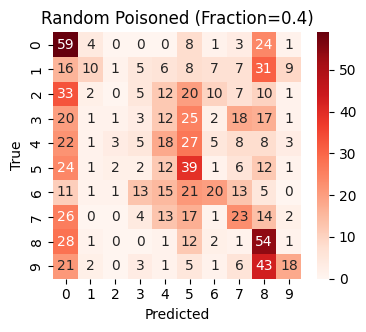

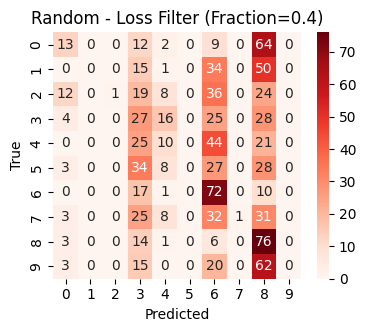

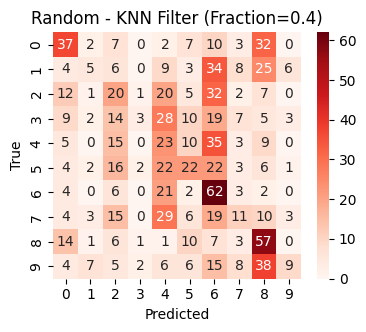

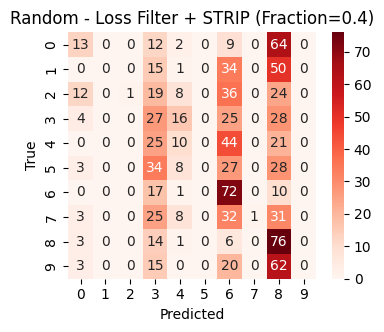

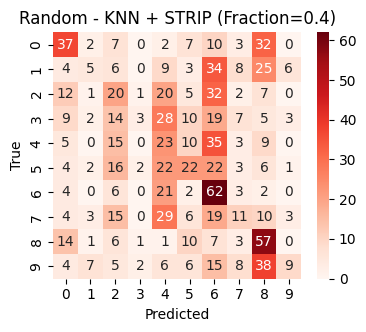

In [ ]:
# predictions
random_preds_poisoned = np.argmax(model_poisoned_random.predict(test_cnn), axis=1)
random_preds_loss = np.argmax(model_defended_loss_random.predict(test_cnn), axis=1)
random_preds_knn = np.argmax(model_defended_knn_random.predict(test_cnn), axis=1)

# STRIP
strip_images_random_loss, strip_idx_random_loss = strip_defence(test_cnn[:1000], train_cnn, model_defended_loss_random)
random_preds_loss_strip = np.argmax(model_defended_loss_random.predict(strip_images_random_loss), axis=1)

strip_images_random_knn, strip_idx_random_knn = strip_defence(test_cnn[:1000], train_cnn, model_defended_knn_random)
random_preds_knn_strip = np.argmax(model_defended_knn_random.predict(strip_images_random_knn), axis=1)

# reports
print_report(label_test_cnn, random_preds_poisoned, "Random Poisoned: ")
print_report(label_test_cnn, random_preds_loss, "Random - Loss Filter: ")
print_report(label_test_cnn, random_preds_knn, "Random - KNN Filter: ")
print_report(label_test_cnn[:1000][strip_idx_random_loss], random_preds_loss_strip, "Random - Loss Filter + STRIP: ")
print_report(label_test_cnn[:1000][strip_idx_random_knn], random_preds_knn_strip, "Random - KNN + STRIP: ")

# confusion matrices
plot_confusion(label_test_cnn, random_preds_poisoned, f"Random Poisoned (Fraction={poison_fraction_random})")
plot_confusion(label_test_cnn, random_preds_loss, f"Random - Loss Filter (Fraction={poison_fraction_random})")
plot_confusion(label_test_cnn, random_preds_knn, f"Random - KNN Filter (Fraction={poison_fraction_random})")
plot_confusion(label_test_cnn[:1000][strip_idx_random_loss], random_preds_loss_strip, f"Random - Loss Filter + STRIP (Fraction={poison_fraction_random})")
plot_confusion(label_test_cnn[:1000][strip_idx_random_knn], random_preds_knn_strip, f"Random - KNN + STRIP (Fraction={poison_fraction_random})")

###Targeted Poisoning

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
Targeted Poisoned: 
Weighted Avg: P=27.28% R=28.00% F1=24.99%
Overall accuracy: 28.00%

Targeted - Loss Filter: 
Weighted Avg: P=33.24% R=30.00% F1=28.25%
Overall accuracy: 30.00%

Targeted - KNN Filter: 
Weighted Avg: P=34.09% R=26.20% F1=24.78%
Overall accuracy: 26.20%

Targeted - Loss Filter + STRIP: 
Weighted Avg: P=33.24% R=30.00% F1=28.25%
Overall accuracy: 30.00%

Targeted - KNN + STRIP: 
Weighted Avg: P=34.09% R=26.20% F1=24.78%
Overall accuracy: 26.20%



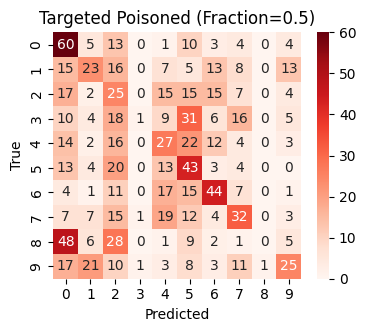

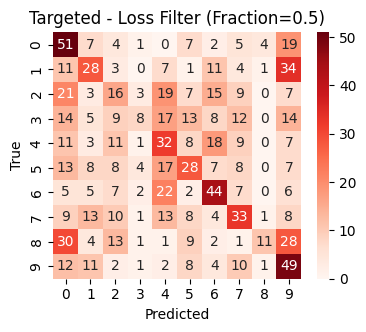

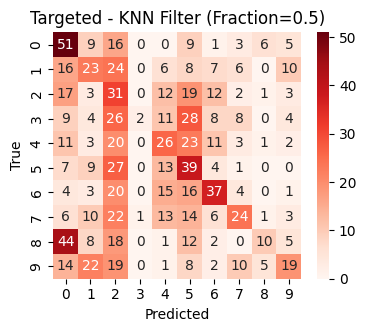

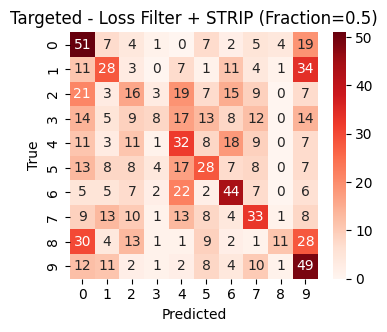

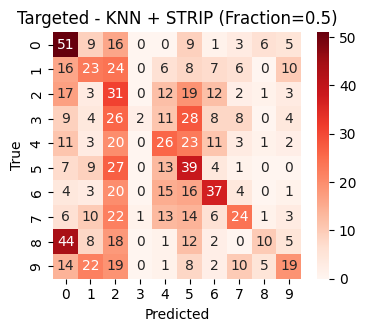

In [ ]:
# predictions
targeted_preds_poisoned = np.argmax(model_poisoned_targeted.predict(test_cnn), axis=1)
targeted_preds_loss = np.argmax(model_defended_loss_targeted.predict(test_cnn), axis=1)
targeted_preds_knn = np.argmax(model_defended_knn_targeted.predict(test_cnn), axis=1)

# STRIP
strip_images_targeted_loss, strip_idx_targeted_loss = strip_defence(test_cnn[:1000], train_cnn, model_defended_loss_targeted)
targeted_preds_loss_strip = np.argmax(model_defended_loss_targeted.predict(strip_images_targeted_loss), axis=1)

strip_images_targeted_knn, strip_idx_targeted_knn = strip_defence(test_cnn[:1000], train_cnn, model_defended_knn_targeted)
targeted_preds_knn_strip = np.argmax(model_defended_knn_targeted.predict(strip_images_targeted_knn), axis=1)

# reports
print_report(label_test_cnn, targeted_preds_poisoned, "Targeted Poisoned: ")
print_report(label_test_cnn, targeted_preds_loss, "Targeted - Loss Filter: ")
print_report(label_test_cnn, targeted_preds_knn, "Targeted - KNN Filter: ")
print_report(label_test_cnn[:1000][strip_idx_targeted_loss], targeted_preds_loss_strip, "Targeted - Loss Filter + STRIP: ")
print_report(label_test_cnn[:1000][strip_idx_targeted_knn], targeted_preds_knn_strip, "Targeted - KNN + STRIP: ")

# confusion matrices
plot_confusion(label_test_cnn, targeted_preds_poisoned, f"Targeted Poisoned (Fraction={poison_fraction_targeted})")
plot_confusion(label_test_cnn, targeted_preds_loss, f"Targeted - Loss Filter (Fraction={poison_fraction_targeted})")
plot_confusion(label_test_cnn, targeted_preds_knn, f"Targeted - KNN Filter (Fraction={poison_fraction_targeted})")
plot_confusion(label_test_cnn[:1000][strip_idx_targeted_loss], targeted_preds_loss_strip, f"Targeted - Loss Filter + STRIP (Fraction={poison_fraction_targeted})")
plot_confusion(label_test_cnn[:1000][strip_idx_targeted_knn], targeted_preds_knn_strip, f"Targeted - KNN + STRIP (Fraction={poison_fraction_targeted})")

###Backdoor Poisoning

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
STRIP: accepted 1000/1000 samples
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
STRIP: accepted 500/1000 samples
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Backdoor (Triggered) - STRIP: 
Weighted Avg: P=34.89% R=32.80% F1=31.03%
Overall accuracy: 32.80%



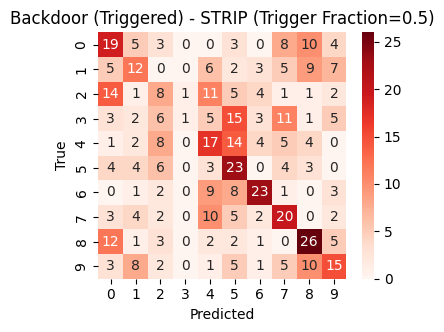

ASR - STRIP: 0.128
STRIP: accepted 500/1000 samples
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
STRIP: accepted 500/1000 samples
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Backdoor (Clean) - Undefended: 
Weighted Avg: P=35.87% R=33.70% F1=32.25%
Overall accuracy: 33.70%

Backdoor (Clean) - Loss Filter: 
Weighted Avg: P=32.27% R=32.50% F1=31.68%
Overall accuracy: 32.50%

Backdoor (Clean) - KNN Filter: 
Weighted Avg: P=33.81% R=31.60% F1=28.94%
Overall accuracy: 31.60%

Backdoor (Clean) - Loss Filter + STRIP: 
Weighted Avg: P=32.27% R=32.50% F1=31.68%
Overall accuracy: 32.50%

Backdoor (Clean) - KNN + STRIP: 
Weighted Avg: P=33.81% R=31.60% F1=28.94%
Overall accuracy: 31.60%

Backdoor (Triggered) - Undefended: 
Weighted Avg: P=33.14% R=21.20% F1=20.70%
Overall accuracy: 21.20%

Backdoor (Triggered) - Loss Filter: 
Weighted Avg: P=30.19% R=21.80% F1=21.74%
Overall accuracy: 21.80%

Backdoor (Triggered) - KNN Filter: 
Weighted Avg: P=31.40% R=20.60% F1=19.07%
Overall accuracy: 20.60%

Backdoor (Tr

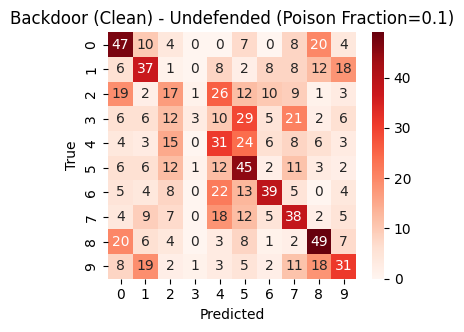

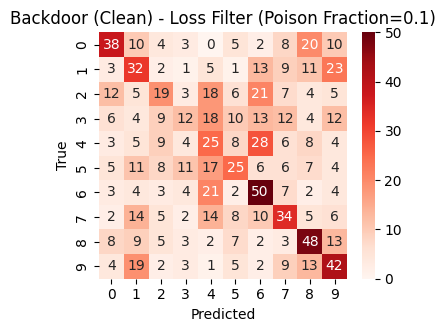

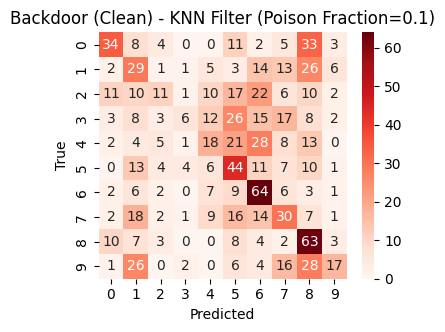

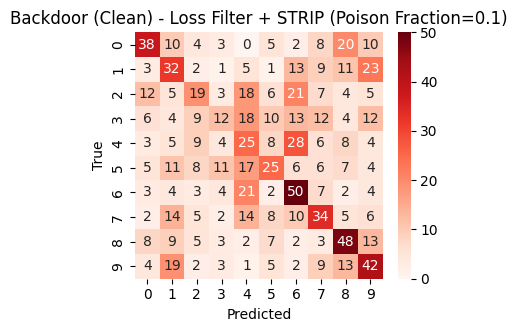

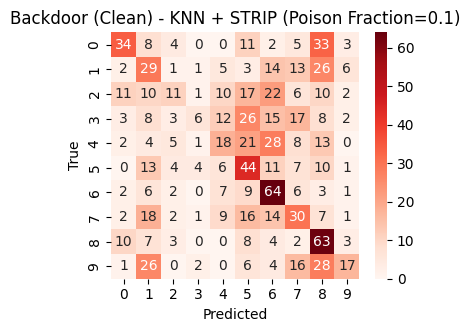

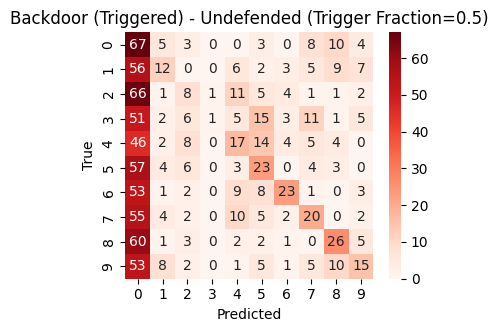

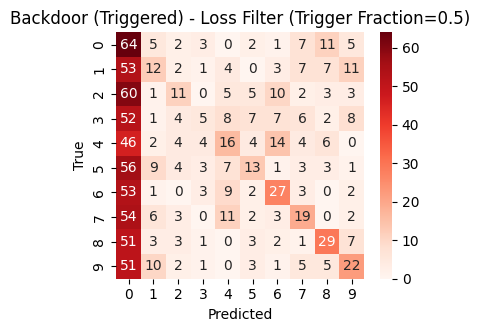

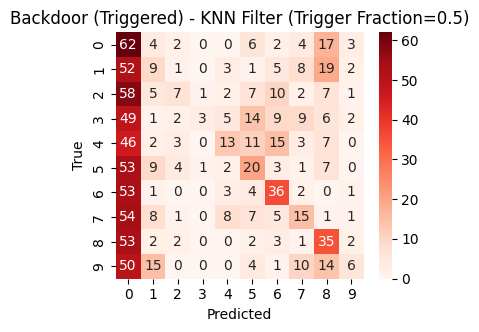

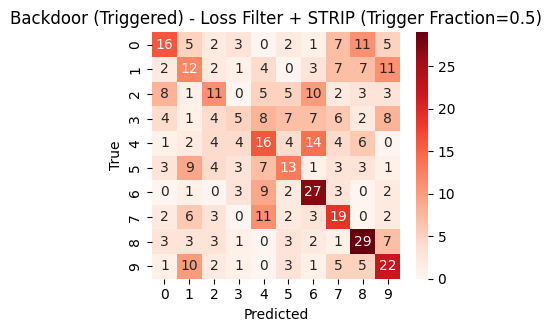

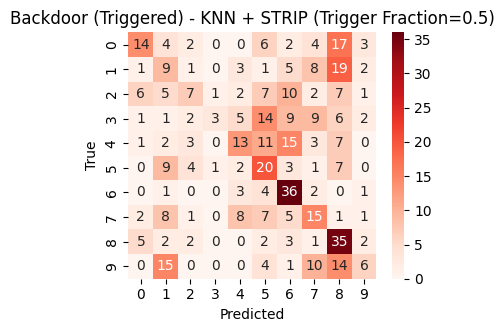

In [ ]:
# create a mixed test set wjhere only a fraction have the trigger
trigger_fraction = 0.5
n_triggered = int(len(test_cnn) * trigger_fraction)
trigger_indices = np.random.choice(len(test_cnn), n_triggered, replace=False)

test_triggered = test_cnn.copy()
test_triggered[trigger_indices] = add_trigger(test_cnn[trigger_indices])

# predictions - clean test set
backdoor_clean_preds_poisoned = np.argmax(model_backdoor.predict(test_cnn), axis=1)
backdoor_clean_preds_loss = np.argmax(model_defended_loss_backdoor.predict(test_cnn), axis=1)
backdoor_clean_preds_knn = np.argmax(model_defended_knn_backdoor.predict(test_cnn), axis=1)

# predictions - triggered test set
backdoor_triggered_preds_poisoned = np.argmax(model_backdoor.predict(test_triggered), axis=1)
backdoor_triggered_preds_loss = np.argmax(model_defended_loss_backdoor.predict(test_triggered), axis=1)
backdoor_triggered_preds_knn = np.argmax(model_defended_knn_backdoor.predict(test_triggered), axis=1)

# STRIP - clean test set
strip_images_backdoor_clean_loss, strip_idx_backdoor_clean_loss = strip_defence(test_cnn[:1000], train_cnn, model_defended_loss_backdoor)
backdoor_clean_preds_loss_strip = np.argmax(model_defended_loss_backdoor.predict(strip_images_backdoor_clean_loss), axis=1)

strip_images_backdoor_clean_knn, strip_idx_backdoor_clean_knn = strip_defence(test_cnn[:1000], train_cnn, model_defended_knn_backdoor)
backdoor_clean_preds_knn_strip = np.argmax(model_defended_knn_backdoor.predict(strip_images_backdoor_clean_knn), axis=1)

# STRIP - triggered test set
strip_images_backdoor_triggered, strip_idx_backdoor_triggered = strip_defence(test_triggered[:1000], train_cnn, model_backdoor)
if len(strip_idx_backdoor_triggered) > 0:
    backdoor_triggered_preds_strip = np.argmax(model_backdoor.predict(strip_images_backdoor_triggered), axis=1)
    print_report(label_test_cnn[:1000][strip_idx_backdoor_triggered], backdoor_triggered_preds_strip, "Backdoor (Triggered) - STRIP: ")
    plot_confusion(label_test_cnn[:1000][strip_idx_backdoor_triggered], backdoor_triggered_preds_strip, f"Backdoor (Triggered) - STRIP (Trigger Fraction={trigger_fraction})")
else:
    print("Backdoor (Triggered) - STRIP: All samples rejected")

strip_images_backdoor_triggered_loss, strip_idx_backdoor_triggered_loss = strip_defence(test_triggered[:1000], train_cnn, model_defended_loss_backdoor)
if len(strip_idx_backdoor_triggered_loss) > 0:
    backdoor_triggered_preds_loss_strip = np.argmax(model_defended_loss_backdoor.predict(strip_images_backdoor_triggered_loss), axis=1)
else:
    print("Backdoor (Triggered) - Loss Filter + STRIP: All samples rejected")
    backdoor_triggered_preds_loss_strip = np.array([])

strip_images_backdoor_triggered_knn, strip_idx_backdoor_triggered_knn = strip_defence(test_triggered[:1000], train_cnn, model_defended_knn_backdoor)
if len(strip_idx_backdoor_triggered_knn) > 0:
    backdoor_triggered_preds_knn_strip = np.argmax(model_defended_knn_backdoor.predict(strip_images_backdoor_triggered_knn), axis=1)
else:
    print("Backdoor (Triggered) - KNN + STRIP: All samples rejected")
    backdoor_triggered_preds_knn_strip = np.array([])

# reports - clean test set
print_report(label_test_cnn, backdoor_clean_preds_poisoned, "Backdoor (Clean) - Undefended: ")
print_report(label_test_cnn, backdoor_clean_preds_loss, "Backdoor (Clean) - Loss Filter: ")
print_report(label_test_cnn, backdoor_clean_preds_knn, "Backdoor (Clean) - KNN Filter: ")
print_report(label_test_cnn[:1000][strip_idx_backdoor_clean_loss], backdoor_clean_preds_loss_strip, "Backdoor (Clean) - Loss Filter + STRIP: ")
print_report(label_test_cnn[:1000][strip_idx_backdoor_clean_knn], backdoor_clean_preds_knn_strip, "Backdoor (Clean) - KNN + STRIP: ")

# reports - triggered test set
print_report(label_test_cnn, backdoor_triggered_preds_poisoned, "Backdoor (Triggered) - Undefended: ")
print_report(label_test_cnn, backdoor_triggered_preds_loss, "Backdoor (Triggered) - Loss Filter: ")
print_report(label_test_cnn, backdoor_triggered_preds_knn, "Backdoor (Triggered) - KNN Filter: ")
if len(backdoor_triggered_preds_loss_strip) > 0:
    print_report(label_test_cnn[:1000][strip_idx_backdoor_triggered_loss], backdoor_triggered_preds_loss_strip, "Backdoor (Triggered) - Loss Filter + STRIP: ")
if len(backdoor_triggered_preds_knn_strip) > 0:
    print_report(label_test_cnn[:1000][strip_idx_backdoor_triggered_knn], backdoor_triggered_preds_knn_strip, "Backdoor (Triggered) - KNN + STRIP: ")

# attack success rates
print("ASR - Undefended:", np.mean(backdoor_triggered_preds_poisoned == target_class))
print("ASR - Loss Filter:", np.mean(backdoor_triggered_preds_loss == target_class))
print("ASR - KNN Filter:", np.mean(backdoor_triggered_preds_knn == target_class))
if len(backdoor_triggered_preds_loss_strip) > 0:
    print("ASR - Loss Filter + STRIP:", np.mean(backdoor_triggered_preds_loss_strip == target_class))
if len(backdoor_triggered_preds_knn_strip) > 0:
    print("ASR - KNN + STRIP:", np.mean(backdoor_triggered_preds_knn_strip == target_class))

# confusion matrices - clean test set
plot_confusion(label_test_cnn, backdoor_clean_preds_poisoned, f"Backdoor (Clean) - Undefended (Poison Fraction={poison_fraction_backdoor})")
plot_confusion(label_test_cnn, backdoor_clean_preds_loss, f"Backdoor (Clean) - Loss Filter (Poison Fraction={poison_fraction_backdoor})")
plot_confusion(label_test_cnn, backdoor_clean_preds_knn, f"Backdoor (Clean) - KNN Filter (Poison Fraction={poison_fraction_backdoor})")
plot_confusion(label_test_cnn[:1000][strip_idx_backdoor_clean_loss], backdoor_clean_preds_loss_strip, f"Backdoor (Clean) - Loss Filter + STRIP (Poison Fraction={poison_fraction_backdoor})")
plot_confusion(label_test_cnn[:1000][strip_idx_backdoor_clean_knn], backdoor_clean_preds_knn_strip, f"Backdoor (Clean) - KNN + STRIP (Poison Fraction={poison_fraction_backdoor})")

# confusion matrices - triggered test set
plot_confusion(label_test_cnn, backdoor_triggered_preds_poisoned, f"Backdoor (Triggered) - Undefended (Trigger Fraction={trigger_fraction})")
plot_confusion(label_test_cnn, backdoor_triggered_preds_loss, f"Backdoor (Triggered) - Loss Filter (Trigger Fraction={trigger_fraction})")
plot_confusion(label_test_cnn, backdoor_triggered_preds_knn, f"Backdoor (Triggered) - KNN Filter (Trigger Fraction={trigger_fraction})")
if len(backdoor_triggered_preds_loss_strip) > 0:
    plot_confusion(label_test_cnn[:1000][strip_idx_backdoor_triggered_loss], backdoor_triggered_preds_loss_strip, f"Backdoor (Triggered) - Loss Filter + STRIP (Trigger Fraction={trigger_fraction})")
if len(backdoor_triggered_preds_knn_strip) > 0:
    plot_confusion(label_test_cnn[:1000][strip_idx_backdoor_triggered_knn], backdoor_triggered_preds_knn_strip, f"Backdoor (Triggered) - KNN + STRIP (Trigger Fraction={trigger_fraction})")

Computing entropy for clean samples...
Computing entropy for triggered samples...


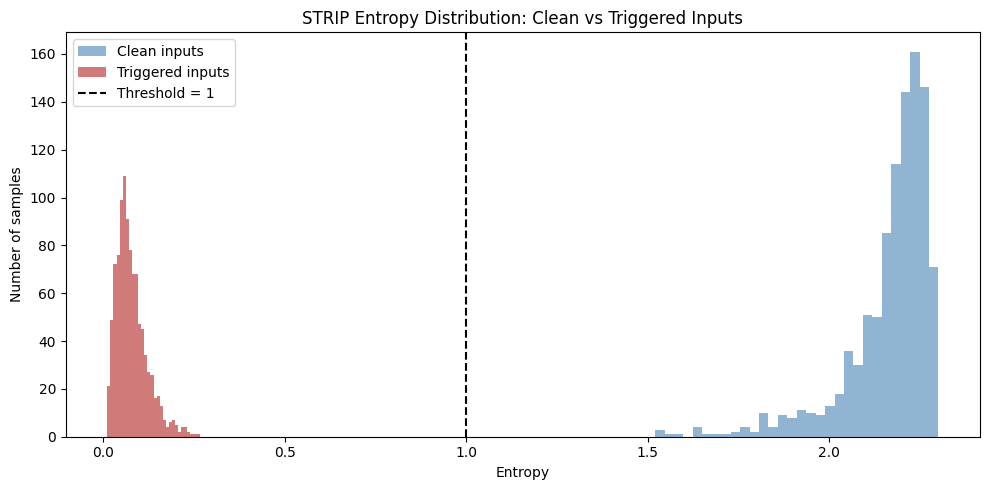


Clean accepted:     1000/1000 (100.0%)
Triggered accepted: 0/1000 (0.0%)
Triggered rejected: 1000/1000 (100.0%)


In [ ]:
def plot_strip_entropy(clean_images, triggered_images, clean_ref_images, model,
                       n_samples=100, n_blends=64, entropy_threshold=1):
    #compute entropy of predictions
    def compute_entropy(image):
        blended = np.array([
            0.5 * image + 0.5 * clean_ref_images[j]
            for j in np.random.choice(len(clean_ref_images), n_blends, replace=False)
        ])
        preds = model.predict(blended, verbose=0)
        mean_pred = np.mean(preds, axis=0)
        #higher entropy data is accepted
        return -np.sum(mean_pred * np.log(mean_pred + 1e-8))

    print("Computing entropy for clean samples...")
    clean_entropies = [compute_entropy(clean_images[i]) for i in range(n_samples)]
    print("Computing entropy for triggered samples...")
    triggered_entropies = [compute_entropy(triggered_images[i]) for i in range(n_samples)]

    plt.figure(figsize=(10, 5))
    plt.hist(clean_entropies, bins=30, alpha=0.6, color='steelblue', label='Clean inputs')
    plt.hist(triggered_entropies, bins=30, alpha=0.6, color='firebrick', label='Triggered inputs')
    plt.axvline(x=entropy_threshold, color='black', linestyle='--', linewidth=1.5, label=f'Threshold = {entropy_threshold}')
    plt.xlabel('Entropy')
    plt.ylabel('Number of samples')
    plt.title('STRIP Entropy Distribution: Clean vs Triggered Inputs')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # print summary
    clean_accepted = sum(e >= entropy_threshold for e in clean_entropies)
    triggered_accepted = sum(e >= entropy_threshold for e in triggered_entropies)
    print(f"\nClean accepted:     {clean_accepted}/{n_samples} ({clean_accepted/n_samples*100:.1f}%)")
    print(f"Triggered accepted: {triggered_accepted}/{n_samples} ({triggered_accepted/n_samples*100:.1f}%)")
    print(f"Triggered rejected: {n_samples - triggered_accepted}/{n_samples} ({(n_samples - triggered_accepted)/n_samples*100:.1f}%)")


test_triggered_vis = add_trigger(test_cnn[:1000])
plot_strip_entropy(
    clean_images=test_cnn[:1000],
    triggered_images=test_triggered_vis,
    clean_ref_images=train_cnn,
    model=model_backdoor,
    n_samples=1000,
    entropy_threshold=1
)

##Evasion Attacks

###FGSM

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
FGSM ATTACKED CNN: 
Weighted Avg: P=18.97% R=18.40% F1=16.67%
Overall accuracy: 18.40%

FGSM TRAINED CNN: 
Weighted Avg: P=26.78% R=25.50% F1=23.29%
Overall accuracy: 25.50%

PGD TRAINED FGSM ATTACK: 
Weighted Avg: P=24.33% R=23.30% F1=21.75%
Overall accuracy: 23.30%

FGSM ATTACKED CNN (Squeezed): 
Weighted Avg: P=22.14% R=23.50% F1=20.80%
Overall accuracy: 23.50%

FGSM TRAINED CNN (Squeezed): 
Weighted Avg: P=23.12% R=26.10% F1=22.85%
Overall accuracy: 26.10%

PGD TRAINED FGSM ATTACK (Squeezed): 
Weighted Avg: P=19.55% R=24.90% F1=21.19%
Overall accuracy: 24.90%



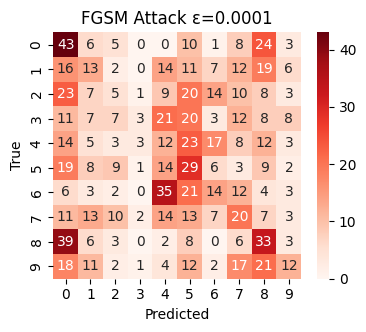

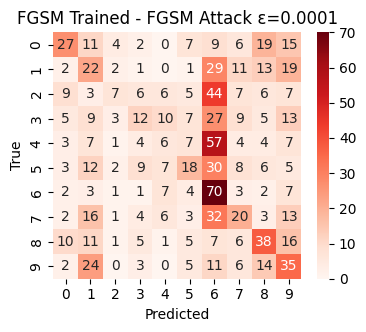

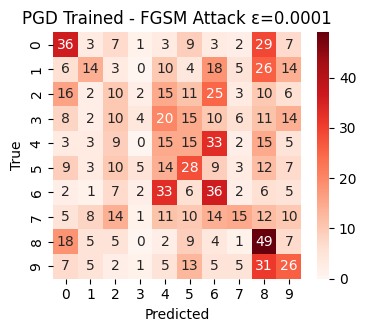

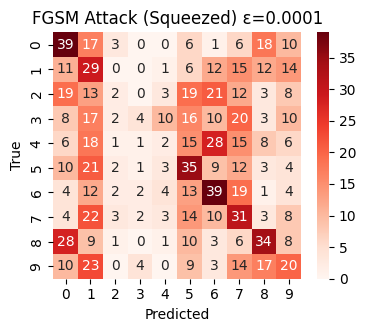

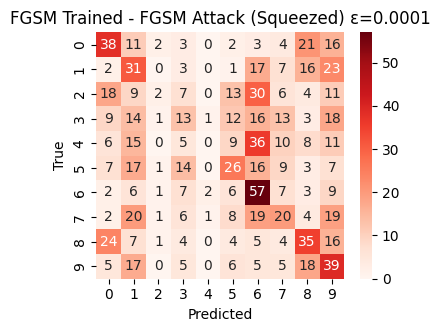

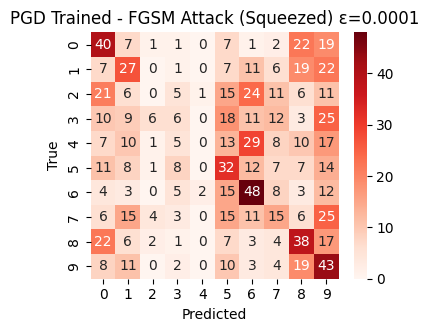

In [ ]:
fgsm_preds_clean = np.argmax(model_clean.predict(clean_fgsm_attack), axis=1)
fgsm_preds_fgsm_trained = np.argmax(model_fgsm.predict(fgsm_trained_fgsm_attack), axis=1)
fgsm_preds_pgd_trained = np.argmax(model_pgd.predict(pgd_trained_fgsm_attack), axis=1)
fgsm_preds_squeezed_clean = np.argmax(model_clean.predict(fgsm_squeezed_clean), axis=1)
fgsm_preds_squeezed_fgsm_trained = np.argmax(model_fgsm.predict(fgsm_squeezed_fgsm_trained), axis=1)
fgsm_preds_squeezed_pgd_trained = np.argmax(model_pgd.predict(fgsm_squeezed_pgd_trained), axis=1)

print_report(label_test_cnn, fgsm_preds_clean, "FGSM ATTACKED CNN: ")
print_report(label_test_cnn, fgsm_preds_fgsm_trained, "FGSM TRAINED CNN: ")
print_report(label_test_cnn, fgsm_preds_pgd_trained, "PGD TRAINED FGSM ATTACK: ")
print_report(label_test_cnn, fgsm_preds_squeezed_clean, "FGSM ATTACKED CNN (Squeezed): ")
print_report(label_test_cnn, fgsm_preds_squeezed_fgsm_trained, "FGSM TRAINED CNN (Squeezed): ")
print_report(label_test_cnn, fgsm_preds_squeezed_pgd_trained, "PGD TRAINED FGSM ATTACK (Squeezed): ")

plot_confusion(label_test_cnn, fgsm_preds_clean, f"FGSM Attack ε={fgsm_epsilon}")
plot_confusion(label_test_cnn, fgsm_preds_fgsm_trained, f"FGSM Trained - FGSM Attack ε={fgsm_epsilon}")
plot_confusion(label_test_cnn, fgsm_preds_pgd_trained, f"PGD Trained - FGSM Attack ε={fgsm_epsilon}")
plot_confusion(label_test_cnn, fgsm_preds_squeezed_clean, f"FGSM Attack (Squeezed) ε={fgsm_epsilon}")
plot_confusion(label_test_cnn, fgsm_preds_squeezed_fgsm_trained, f"FGSM Trained - FGSM Attack (Squeezed) ε={fgsm_epsilon}")
plot_confusion(label_test_cnn, fgsm_preds_squeezed_pgd_trained, f"PGD Trained - FGSM Attack (Squeezed) ε={fgsm_epsilon}")

###PGD

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
PGD ATTACKED: 
Weighted Avg: P=21.75% R=21.00% F1=19.24%
Overall accuracy: 21.00%

FGSM TRAINED PGD ATTACK: 
Weighted Avg: P=29.23% R=28.10% F1=25.83%
Overall accuracy: 28.10%

PGD TRAINED PGD ATTACK: 
Weighted Avg: P=26.63% R=25.30% F1=23.79%
Overall accuracy: 25.30%

PGD ATTACKED (Squeezed): 
Weighted Avg: P=23.42% R=25.10% F1=22.25%
Overall accuracy: 25.10%

FGSM TRAINED PGD ATTACK (Squeezed): 
Weighted Avg: P=24.31% R=27.50% F1=24.17%
Overall accuracy: 27.50%

PGD TRAINED PGD ATTACK (Squeezed): 
Weighted Avg: P=20.13% R=25.70% F1=21.92%
Overall accuracy: 25.70%



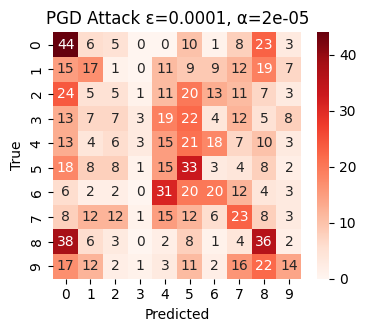

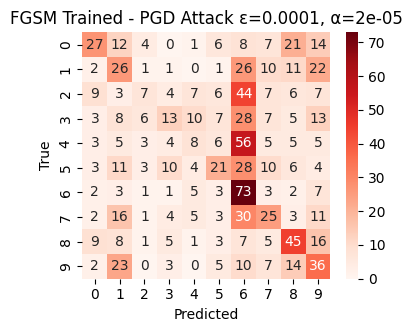

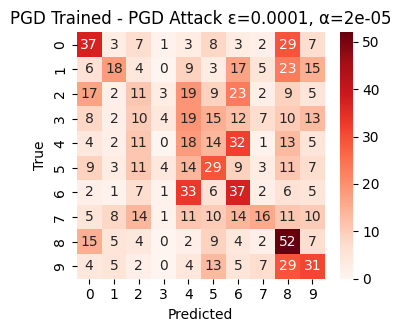

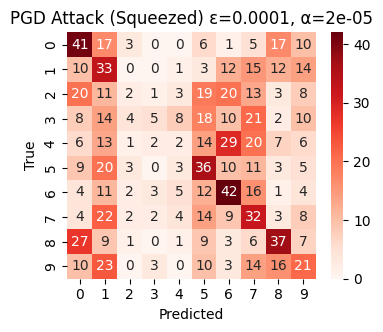

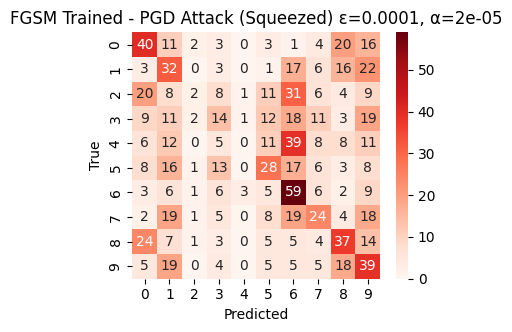

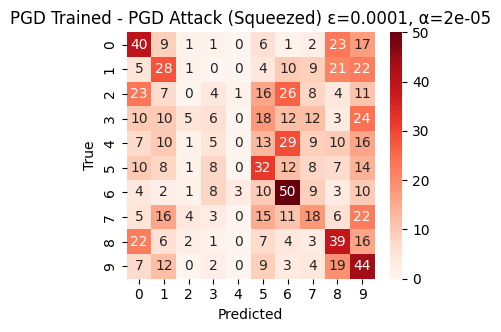

In [ ]:
pgd_preds_clean = np.argmax(model_clean.predict(clean_pgd_attack), axis=1)
pgd_preds_fgsm_trained = np.argmax(model_fgsm.predict(fgsm_trained_pgd_attack), axis=1)
pgd_preds_pgd_trained = np.argmax(model_pgd.predict(pgd_trained_pgd_attack), axis=1)
pgd_preds_squeezed_clean = np.argmax(model_clean.predict(pgd_squeezed_clean), axis=1)
pgd_preds_squeezed_fgsm_trained = np.argmax(model_fgsm.predict(pgd_squeezed_fgsm_trained), axis=1)
pgd_preds_squeezed_pgd_trained = np.argmax(model_pgd.predict(pgd_squeezed_pgd_trained), axis=1)

print_report(label_test_cnn, pgd_preds_clean, "PGD ATTACKED: ")
print_report(label_test_cnn, pgd_preds_fgsm_trained, "FGSM TRAINED PGD ATTACK: ")
print_report(label_test_cnn, pgd_preds_pgd_trained, "PGD TRAINED PGD ATTACK: ")
print_report(label_test_cnn, pgd_preds_squeezed_clean, "PGD ATTACKED (Squeezed): ")
print_report(label_test_cnn, pgd_preds_squeezed_fgsm_trained, "FGSM TRAINED PGD ATTACK (Squeezed): ")
print_report(label_test_cnn, pgd_preds_squeezed_pgd_trained, "PGD TRAINED PGD ATTACK (Squeezed): ")

plot_confusion(label_test_cnn, pgd_preds_clean, f"PGD Attack ε={pgd_epsilon}, α={alpha}")
plot_confusion(label_test_cnn, pgd_preds_fgsm_trained, f"FGSM Trained - PGD Attack ε={pgd_epsilon}, α={alpha}")
plot_confusion(label_test_cnn, pgd_preds_pgd_trained, f"PGD Trained - PGD Attack ε={pgd_epsilon}, α={alpha}")
plot_confusion(label_test_cnn, pgd_preds_squeezed_clean, f"PGD Attack (Squeezed) ε={pgd_epsilon}, α={alpha}")
plot_confusion(label_test_cnn, pgd_preds_squeezed_fgsm_trained, f"FGSM Trained - PGD Attack (Squeezed) ε={pgd_epsilon}, α={alpha}")
plot_confusion(label_test_cnn, pgd_preds_squeezed_pgd_trained, f"PGD Trained - PGD Attack (Squeezed) ε={pgd_epsilon}, α={alpha}")

###DeepFool

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
DeepFool ATTACKED: 
Weighted Avg: P=16.52% R=15.50% F1=15.36%
Overall accuracy: 15.50%

FGSM TRAINED DeepFool ATTACK: 
Weighted Avg: P=17.18% R=17.20% F1=16.22%
Overall accuracy: 17.20%

PGD TRAINED DeepFool ATTACK: 
Weighted Avg: P=18.19% R=17.90% F1=17.19%
Overall accuracy: 17.90%

DeepFool ATTACKED (Squeezed): 
Weighted Avg: P=25.62% R=27.50% F1=24.59%
Overall accuracy: 27.50%

FGSM TRAINED DeepFool ATTACK (Squeezed): 
Weighted Avg: P=25.02% R=26.40% F1=24.52%
Overall accuracy: 26.40%

PGD TRAINED DeepFool ATTACK (Squeezed): 
Weighted Avg: P=21.55% R=27.00% F1=22.75%
Overall accuracy: 27.00%



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


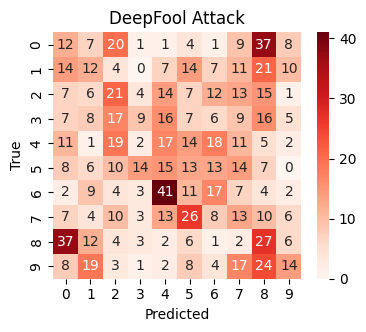

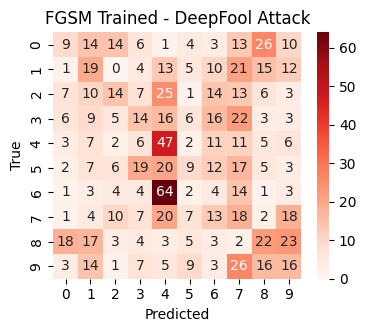

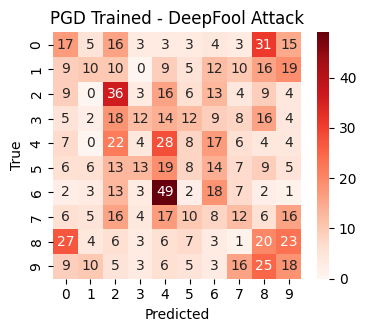

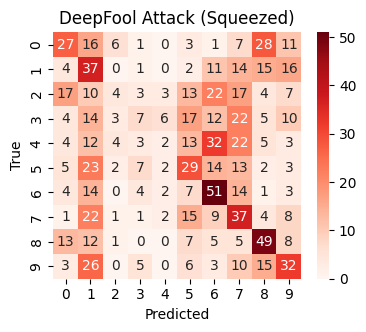

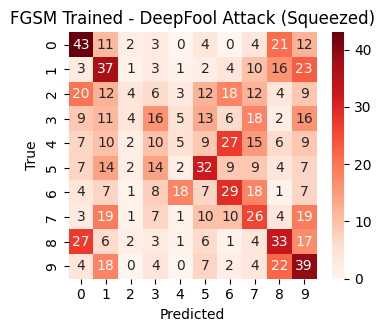

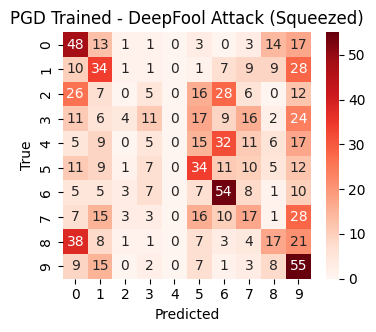

In [ ]:
deepfool_preds_clean = np.argmax(model_clean.predict(clean_deepfool_attack), axis=1)
deepfool_preds_fgsm_trained = np.argmax(model_fgsm.predict(fgsm_trained_deepfool_attack), axis=1)
deepfool_preds_pgd_trained = np.argmax(model_pgd.predict(pgd_trained_deepfool_attack), axis=1)
deepfool_preds_squeezed_clean = np.argmax(model_clean.predict(deepfool_squeezed_clean), axis=1)
deepfool_preds_squeezed_fgsm_trained = np.argmax(model_fgsm.predict(deepfool_squeezed_fgsm_trained), axis=1)
deepfool_preds_squeezed_pgd_trained = np.argmax(model_pgd.predict(deepfool_squeezed_pgd_trained), axis=1)

print_report(label_test_cnn, deepfool_preds_clean, "DeepFool ATTACKED: ")
print_report(label_test_cnn, deepfool_preds_fgsm_trained, "FGSM TRAINED DeepFool ATTACK: ")
print_report(label_test_cnn, deepfool_preds_pgd_trained, "PGD TRAINED DeepFool ATTACK: ")
print_report(label_test_cnn, deepfool_preds_squeezed_clean, "DeepFool ATTACKED (Squeezed): ")
print_report(label_test_cnn, deepfool_preds_squeezed_fgsm_trained, "FGSM TRAINED DeepFool ATTACK (Squeezed): ")
print_report(label_test_cnn, deepfool_preds_squeezed_pgd_trained, "PGD TRAINED DeepFool ATTACK (Squeezed): ")

plot_confusion(label_test_cnn, deepfool_preds_clean, "DeepFool Attack")
plot_confusion(label_test_cnn, deepfool_preds_fgsm_trained, "FGSM Trained - DeepFool Attack")
plot_confusion(label_test_cnn, deepfool_preds_pgd_trained, "PGD Trained - DeepFool Attack")
plot_confusion(label_test_cnn, deepfool_preds_squeezed_clean, "DeepFool Attack (Squeezed)")
plot_confusion(label_test_cnn, deepfool_preds_squeezed_fgsm_trained, "FGSM Trained - DeepFool Attack (Squeezed)")
plot_confusion(label_test_cnn, deepfool_preds_squeezed_pgd_trained, "PGD Trained - DeepFool Attack (Squeezed)")